In [2]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS

from langgraph.graph import StateGraph,START,END

from langchain_ollama import OllamaEmbeddings,ChatOllama

from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.documents import Document



from pydantic import BaseModel
from typing import TypedDict,List
import re

/var/folders/zd/wq0h2pzd4ks66gj19y5_p7br0000gn/T/ipykernel_42515/3358014595.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader
/Users/ryankhurana/Desktop/CRAG-Corrective-RAG-/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.
/Users/ryankhurana/Desktop/CRAG-Corrective-RAG-/venv/lib/python3.13/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a

In [3]:
docs = (
    PyPDFLoader("./documents/book1.pdf").load() +
    PyPDFLoader("./documents/book2.pdf").load() +
    PyPDFLoader("./documents/book3.pdf").load()
)

In [4]:
len(docs)

2123

In [5]:
chunks=RecursiveCharacterTextSplitter(chunk_size=900,chunk_overlap=150).split_documents(docs)

In [6]:
for d in chunks:
    d.page_content=d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [7]:
embedding=OllamaEmbeddings(model="nomic-embed-text")

In [8]:
vector_store=FAISS.from_documents(chunks,embedding)


In [9]:
retriever=vector_store.as_retriever(search_type="similarity",search_kwags={'k':4})

In [ ]:
llm=ChatOllama(model="llama3.1:8b")

In [11]:
class State(TypedDict):
    question:str
    docs:List[Document]

    strips:List[str]#break down the content in document and split into sentence
    kept_strips:List[str]# after filtering down the strips by the LLM on the basis of the relevance to the question
    refined_context:str  # recomposed internal knowledge (joined kept_strips)


    answer:str


In [12]:
def retrive(state:State)->State:
    question=state['question']
    docs=retriever.invoke(question)
    return {"docs":docs}
  

In [13]:
# Sentence-level DECOMPOSER
# -----------------------------
def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]


# FILTER (LLM judge)
class keepordrop(BaseModel):
    keep:bool
filter_prompt=ChatPromptTemplate.from_messages(
    [
        ("system",
             "You are a strict relevance filter.\n"
            "Return keep=true only if the sentence directly helps answer the question.\n"
            "Use ONLY the sentence. Output JSON only.",
        ),
       # sentence => comes from splitting retrieved documents into smaller chunks/sentences.(done using decomposer)
        ("human","Question:{question}\n\nSentences:{sentences}")
    ]
)
llm_structured_output=llm.with_structured_output(keepordrop)#basically forcing the llm to reposne in a particular format
filter_chain=filter_prompt|llm_structured_output
def refine(state:State)->State:
    question=state['question']
    #first bring in the docs from the retriever and then convert those docs in a single string called the context that will be futher decomposed and filter and put together
    docs=state["docs"]
    context="\n\n".join(d.page_content for d in docs)#extract page_content join those together while having 2 line break btw them
    #1 Decompose
    decomposed_sentences=decompose_to_sentences(context)
    #2) then send these sentences to an llm to filer out the relevant sentences
    kept:List[str]=[]#only keep the things relevant to the question
    for s in decomposed_sentences:
        if filter_chain.invoke({"question":question,"sentences":s}).keep:
            kept.append(s)
    #after filtering out the sentences they are put in list and have to put back together 
    final_filtered_text="\n".join(s for s in kept)   
    return {
        "strips": decomposed_sentences,
        "kept_strips": kept,
        "refined_context": final_filtered_text,
    }





In [14]:
answer_prompt=ChatPromptTemplate.from_messages([
    (
        "system","You are a helpful ML tutor. Answer ONLY using the provided refined bullets.\n"
        "If the bullets are empty or insufficient, say: 'I don't know based on the provided books.'"
    ),
    (
        "human","Question: {question}\n\nRefined context:\n{refined_context}",
    )
]
)
def generate(state:State)->State:
    chain=(answer_prompt|llm)
    output=chain.invoke({"question":state["question"],"refined_context":state["refined_context"]})
    return {"answer":output.content}

In [15]:
g=StateGraph(State)
g.add_node("retrive",retrive)
g.add_node("refine",refine)
g.add_node("generate",generate)

g.add_edge(START,"retrive")
g.add_edge("retrive","refine")
g.add_edge("refine","generate")
g.add_edge("generate",END)


In [16]:
app=g.compile()

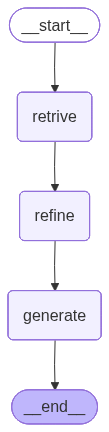

In [17]:
app

In [30]:
res = app.invoke({
    "question": "Explain the supervised machine learning",
    "docs": [],
    "strips": [],
    "kept_strips": [],
    "refined_context": "",
    "answer": ""
})

In [31]:
print(res["answer"])
print("*"*100)
print("\n")
print("Refined context")
print(res['refined_context'])
print("*"*100)
print("\n")
for d in res["docs"]:
    print(d.page_content)


Here are the refined bullets explaining supervised machine learning:

• Supervised learning involves training a model with labeled data, where each example includes both input features and the corresponding desired output or label.
• The training data for supervised learning includes the desired solutions, called labels.
• A typical supervised learning task is classification, where the goal is to predict a categorical label (e.g., spam or ham) based on input features.
• In supervised learning, the model learns to map inputs to outputs by minimizing the difference between predicted and actual labels.
****************************************************************************************************


Refined context
Supervised learning In supervised learning, the training data you feed to the algorithm includes the desired solutions, called labels (Figure 1-5).
A labeled training set for supervised learning (e.g., spam classification) A typical supervised learning task is classificatio